# Open-Pit Gold Mine — Haul-Truck Predictive Maintenance
**Daily Data Analytics Project · Day 15**

## Business question
*An open-pit gold mine in western Azerbaijan runs 48 haul trucks (CAT 777G, Komatsu HD785, BelAZ 7555B) on two pits, two shifts a day. Maintenance today is "PM every ~500 engine hours, fix the rest when it breaks". Unplanned breakdowns stop ore haulage and cost far more than a planned repair. The maintenance manager asks: **how much do breakdowns cost us, what drives them, do the trucks' sensors warn us in advance — and can a daily early-warning list catch failures early enough to pay for the extra inspections?***

Approach:
1. Clean two years of daily telemetry (unit mix-ups, stuck sensors, messy IDs and dates, duplicates).
2. Reliability KPIs: availability, MTBF, MTTR, breakdown rate per 1,000 h, cost of unplanned downtime.
3. EDA: which components fail, and how the rate depends on PM overdue hours, truck age and pit.
4. **Precursor analysis**: sensor deviation from each truck's own baseline, aligned on days-to-breakdown.
5. Baseline alerting: a per-truck **z-score control chart** (the rule many sites use).
6. **Gradient-boosted early-warning model** (breakdown in the next 1–7 days) with a **time-based split and purge gap**, evaluated as *events* (inspections triggered, failures caught, lead time) and in **AZN**, with the alert threshold chosen on a validation period.
7. Today's watch list and recommendations.

> Data is **synthetic** (fixed seed), generated by `data/generate_data.py`. Money assumptions: lost haulage margin **420 AZN per truck-hour** of downtime; an inspection costs 4 h of truck time + 300 AZN; an inspection finds a developing fault 80% of the time; a fault caught early costs 35% of the repair cost and 30% of the downtime of a breakdown.

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.inspection import permutation_importance
import pdm
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.edgecolor": "#898781", "axes.titleweight": "bold"})
COMPS = ["engine", "transmission", "hydraulics_brakes", "suspension"]
COL = dict(zip(COMPS, ["#d03b3b", "#eb6834", "#2a78d6", "#1baf7a"]))
pd.set_option("display.float_format", "{:,.3f}".format); pd.set_option("display.max_colwidth", None)
tele, mlog, fleet = pdm.load_raw()
mlog["date"] = pd.to_datetime(mlog.date)
print(tele.shape, mlog.shape, fleet.shape); tele.head()

(32882, 13) (1835, 6) (48, 5)


,date,truck_id,engine_hours,payload_t_avg,overload_share,ambient_c,coolant_temp_c,oil_pressure_kpa,trans_oil_temp_c,brake_temp_c,hydraulic_pressure_bar,vibration_rms_mm_s,fuel_rate_lph
0,2025-03-16,HT-24,19.000,58.400,0.202,2.000,87.400,386.700,80.800,196.000,204.700,3.860,73.600
1,2026-05-28,HT-44,19.200,87.600,0.096,16.100,87.900,336.700,84.400,219.400,207.300,4.300,97.900
2,2026-07-18,HT-02,18.600,92.700,0.161,20.100,89.400,362.000,83.800,158.700,202.100,5.260,95.600
3,2025-03-31,HT-40,20.400,90.200,0.102,7.200,86.600,395.400,82.300,171.000,209.300,4.570,105.400
4,2026-08-06,HT-39,20.500,84.400,0.092,22.100,88.000,390.400,82.100,164.400,211.400,4.100,84.900


## 1. Data quality check

In [2]:
df, log = pdm.clean(tele)
checks = {**log,
 "Truck-days after cleaning": len(df),
 "Trucks": df.truck_id.nunique(),
 "Date range": f"{df.date.min():%Y-%m-%d} → {df.date.max():%Y-%m-%d}",
 "Coolant range after fix (°C)": f"{df.coolant_temp_c.min():.1f} – {df.coolant_temp_c.max():.1f}",
 "Maintenance events (PM / breakdown)": f"{(mlog.event_type == 'PM service').sum()} / {(mlog.event_type == 'Breakdown').sum()}",
 "Breakdowns without telemetry on that day": int((~mlog[mlog.event_type == 'Breakdown'].set_index(['truck_id', 'date']).index.isin(df.set_index(['truck_id', 'date']).index)).sum()),
}
pd.Series(checks).to_frame("result")

,result
Raw telemetry rows,32882
Truck IDs re-formatted (case / spaces / zero-padding),251
Dates in dd.mm.yyyy format parsed,657
Duplicate truck-day rows dropped,150
Coolant readings in °F converted,21
Stuck-sensor readings set to missing,34
Zero payload (scale failure) set to missing,40
Remaining missing sensor values (dropouts),1390
Truck-days after cleaning,32732
Trucks,48


Fixes: truck IDs typed as `ht-07`, `HT-7` or with a trailing space are normalised to `HT-07`; about 2% of dates came from a regional export in `dd.mm.yyyy`; 150 duplicate rows from a repeated upload are dropped. One truck's firmware sent coolant temperature in **°F** for three weeks (≈190 "°C"), which would look like a severe engine fault, so values above 150 are converted back. An oil-pressure sensor that stuck at 372.0 kPa for weeks is detected as **five or more identical consecutive readings** and set to missing: a frozen sensor hides exactly the drift we want to detect. Zero payloads (weighing failures) are set to missing. Remaining sensor dropouts (≈0.6%) are left as missing; the rolling features and the gradient-boosting model handle them natively.

In [3]:
df = pdm.add_maintenance_context(df, mlog, fleet)
df, FEATS = pdm.build_features(df)
bd = mlog[mlog.event_type == "Breakdown"].copy()
pm = mlog[mlog.event_type == "PM service"]
truth = pd.DataFrame(json.loads((pdm.DATA / "ground_truth.json").read_text()))
print(len(FEATS), "features"); df[["truck_id", "date", "oil_pressure_kpa", "oil_pressure_kpa__z3", "hours_since_pm", "days_to_breakdown", "y"]].dropna().head()

38 features


,truck_id,date,oil_pressure_kpa,oil_pressure_kpa__z3,hours_since_pm,days_to_breakdown,y
22,HT-01,2024-11-24,394.700,1.884,0.000,5.000,1
23,HT-01,2024-11-25,402.800,1.032,18.900,4.000,1
24,HT-01,2024-11-26,391.800,0.547,36.200,3.000,1
25,HT-01,2024-11-27,411.100,-0.144,54.400,2.000,1
26,HT-01,2024-11-28,399.800,-0.000,73.400,1.000,1


## 2. Headline reliability KPIs

In [4]:
cal_h = 48 * 24 * ((df.date.max() - df.date.min()).days + 1)
op_h = df.engine_hours.sum()
bd["unplanned_azn"] = bd.cost_azn + bd.downtime_h * pdm.MARGIN_PER_H
gt = df.groupby("truck_id")  # engine hours at which each PM was done = hours on the last day before the reset
pm_at = (gt.hours_since_pm.shift() + gt.engine_hours.shift())[gt.hours_since_pm.diff() < -100].dropna()
K = {
 "Fleet / period": f"48 trucks, {df.date.min():%b %Y} – {df.date.max():%b %Y}",
 "Physical availability": f"{1 - (bd.downtime_h.sum() + pm.downtime_h.sum()) / cal_h:.1%}",
 "Unplanned breakdowns": f"{len(bd):,} ({len(bd) / 48 / 2:.1f} per truck per year)",
 "MTBF (operating hours between breakdowns)": f"{op_h / len(bd):,.0f} h",
 "MTTR (mean downtime per breakdown)": f"{bd.downtime_h.mean():.1f} h",
 "Breakdowns per 1,000 engine hours": f"{1000 * len(bd) / op_h:.2f}",
 "Share of downtime that is unplanned": f"{bd.downtime_h.sum() / (bd.downtime_h.sum() + pm.downtime_h.sum()):.1%}",
 "Cost of breakdowns (repair + lost margin)": f"AZN {bd.unplanned_azn.sum() / 1e6:,.2f} M ({bd.unplanned_azn.sum() / 2 / 1e6:,.2f} M a year)",
 "  of which lost haulage margin": f"{(bd.downtime_h * pdm.MARGIN_PER_H).sum() / bd.unplanned_azn.sum():.1%}",
 "PM services done late (> 550 h)": f"{(pm_at > 550).mean():.1%} of {len(pm_at)} PMs",
}
KPI = pd.Series(K).to_frame("value"); KPI

,value
Fleet / period,"48 trucks, Nov 2024 – Oct 2026"
Physical availability,95.4%
Unplanned breakdowns,657 (6.8 per truck per year)
MTBF (operating hours between breakdowns),961 h
MTTR (mean downtime per breakdown),37.6 h
"Breakdowns per 1,000 engine hours",1.04
Share of downtime that is unplanned,63.5%
Cost of breakdowns (repair + lost margin),AZN 23.96 M (11.98 M a year)
of which lost haulage margin,43.3%
PM services done late (> 550 h),29.2% of 1127 PMs


## 3. Exploratory analysis — what fails, and when

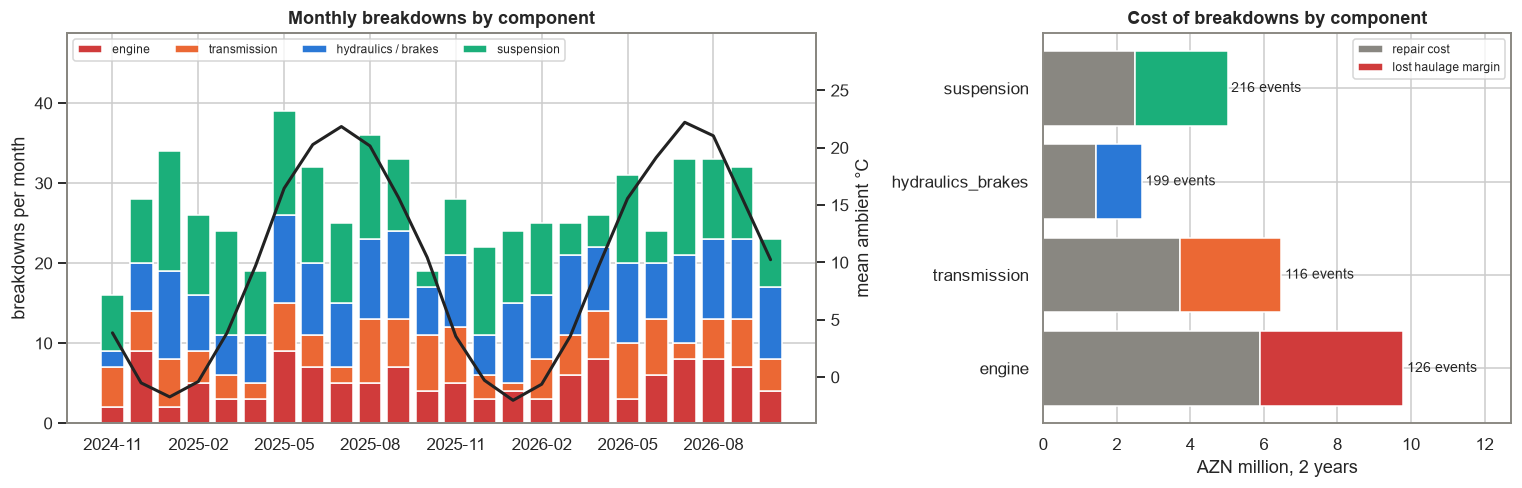

,n,repair,down,lost,cost_per_event_azn,mttr_h
component,,,,,,
engine,126,5904422,"9,258.200","3,888,444.000","77,721.159",73.478
transmission,116,3715202,"6,567.900","2,758,518.000","55,807.931",56.620
hydraulics_brakes,199,1447214,"2,936.300","1,233,246.000","13,469.648",14.755
suspension,216,2507924,"5,960.500","2,503,410.000","23,200.620",27.595


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
mon = bd.assign(m=bd.date.dt.to_period("M")).pivot_table(index="m", columns="component", values="truck_id", aggfunc="size", fill_value=0)[COMPS]
x = np.arange(len(mon)); bottom = np.zeros(len(mon))
for c in COMPS:
    ax[0].bar(x, mon[c], bottom=bottom, color=COL[c], label=c.replace("_", " / "), width=0.8); bottom += mon[c].values
amb = df.groupby(df.date.dt.to_period("M")).ambient_c.mean().reindex(mon.index)
a2 = ax[0].twinx(); a2.plot(x, amb.values, color="#222", lw=2, label="ambient °C"); a2.grid(False); a2.set_ylabel("mean ambient °C")
ax[0].set_xticks(x[::3]); ax[0].set_xticklabels([str(p) for p in mon.index[::3]])
ax[0].set_ylabel("breakdowns per month"); ax[0].set_title("Monthly breakdowns by component"); ax[0].legend(loc="upper left", fontsize=8, ncol=4)
ax[0].set_ylim(0, mon.sum(axis=1).max() * 1.25); a2.set_ylim(amb.min() - 2, amb.max() * 1.35)
cost = bd.groupby("component").agg(n=("truck_id", "size"), repair=("cost_azn", "sum"), down=("downtime_h", "sum"))
cost["lost"] = cost.down * pdm.MARGIN_PER_H; cost = cost.loc[COMPS]
ax[1].barh(cost.index, cost.repair / 1e6, color="#898781", label="repair cost")
ax[1].barh(cost.index, cost.lost / 1e6, left=cost.repair / 1e6, color=[COL[c] for c in COMPS], label="lost haulage margin")
for i, (c, r) in enumerate(cost.iterrows()):
    ax[1].text((r.repair + r.lost) / 1e6 + 0.1, i, f"{int(r.n)} events", va="center", fontsize=9)
ax[1].set_xlabel("AZN million, 2 years"); ax[1].set_title("Cost of breakdowns by component"); ax[1].legend(fontsize=8, loc="upper right")
ax[1].set_xlim(0, (cost.repair + cost.lost).max() / 1e6 * 1.3)
plt.tight_layout(); plt.savefig("images/eda_overview.png", bbox_inches="tight"); plt.show()
cost.assign(cost_per_event_azn=(cost.repair + cost.lost) / cost.n, mttr_h=cost.down / cost.n)

Suspension and hydraulics/brakes fail most often, but they are cheap and quick to fix (13–23k AZN per event). **Engine and transmission** failures are rarer, but each one costs 56–78k AZN once lost haulage is counted, so together they make up more than half of the bill. Engine failures peak in the hot summer months. Lost haulage margin is more than 40% of the cost, so **reducing downtime** matters as much as reducing parts cost.

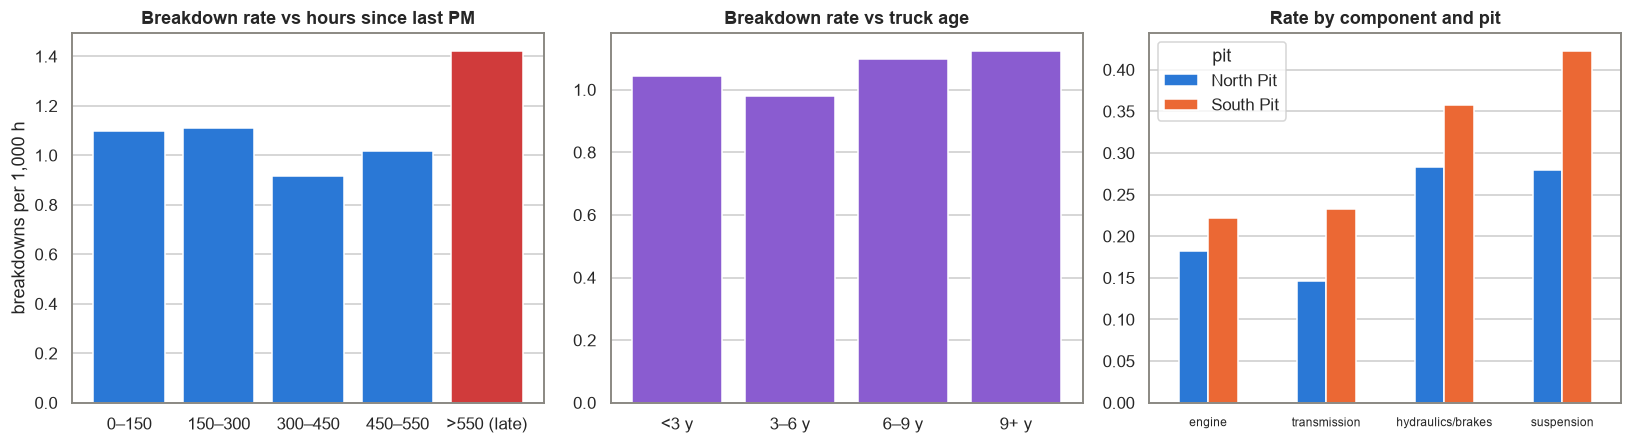

,breakdowns,engine_h,per_1000h
hours_since_pm,,,
0–150,201,"183,068.700",1.100
150–300,195,"175,535.700",1.110
300–450,154,"168,373.600",0.910
450–550,67,"65,960.700",1.020
>550 (late),36,"25,304.900",1.420


,breakdowns,engine_h,per_1000h
age_years,,,
<3 y,72,"68,975.300",1.040
3–6 y,297,"303,508.200",0.980
6–9 y,214,"194,954.500",1.100
9+ y,72,"64,026.400",1.120


component,engine,transmission,hydraulics_brakes,suspension
pit,,,,
North Pit,0.180,0.150,0.280,0.280
South Pit,0.220,0.230,0.360,0.420


In [6]:
bdx = df[df.breakdown_today]  # truck-days on which a breakdown happened
def rate(col, bins, labels):
    cut = pd.cut(df[col], bins, labels=labels)
    return pd.DataFrame({"breakdowns": bdx.groupby(pd.cut(bdx[col], bins, labels=labels), observed=False).size(),
                         "engine_h": df.groupby(cut, observed=False).engine_hours.sum()}).assign(per_1000h=lambda t: 1000 * t.breakdowns / t.engine_h)
r_pm = rate("hours_since_pm", [-1, 150, 300, 450, 550, 2000], ["0–150", "150–300", "300–450", "450–550", ">550 (late)"])
r_age = rate("age_years", [0, 3, 6, 9, 12], ["<3 y", "3–6 y", "6–9 y", "9+ y"])
br = bd.merge(fleet[["truck_id", "pit"]], on="truck_id").groupby(["pit", "component"]).size().unstack()[COMPS]
pp = 1000 * br.div(df.groupby("pit").engine_hours.sum(), axis=0)  # breakdowns per 1,000 h
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].bar(r_pm.index.astype(str), r_pm.per_1000h, color=["#2a78d6"] * 4 + ["#d03b3b"]); ax[0].set_title("Breakdown rate vs hours since last PM"); ax[0].set_ylabel("breakdowns per 1,000 h")
ax[1].bar(r_age.index.astype(str), r_age.per_1000h, color="#8a5cd0"); ax[1].set_title("Breakdown rate vs truck age")
pp.T.plot.bar(ax=ax[2], color=["#2a78d6", "#eb6834"], rot=0); ax[2].set_title("Rate by component and pit"); ax[2].set_xticklabels([c.replace("_brakes", "/brakes") for c in COMPS], fontsize=8); ax[2].set_xlabel("")
for a in ax: a.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig("images/failure_drivers.png", bbox_inches="tight"); plt.show()
display(r_pm.round(2)); display(r_age.round(2)); pp.round(2)

Three drivers stand out. **Late PM**: once a truck goes past 550 h since its last service, the breakdown rate is about 35–40% higher than for trucks serviced on time, and almost a third of PMs are late. **Age** has a weaker effect: trucks older than 6 years fail somewhat more often. **South Pit**, with steeper ramps and more overloading, has clearly more suspension, transmission and brake failures. These explain *how often* trucks fail, but not *which truck will fail this week*. For that we need the sensors.

## 4. Do the sensors warn us? Precursor analysis

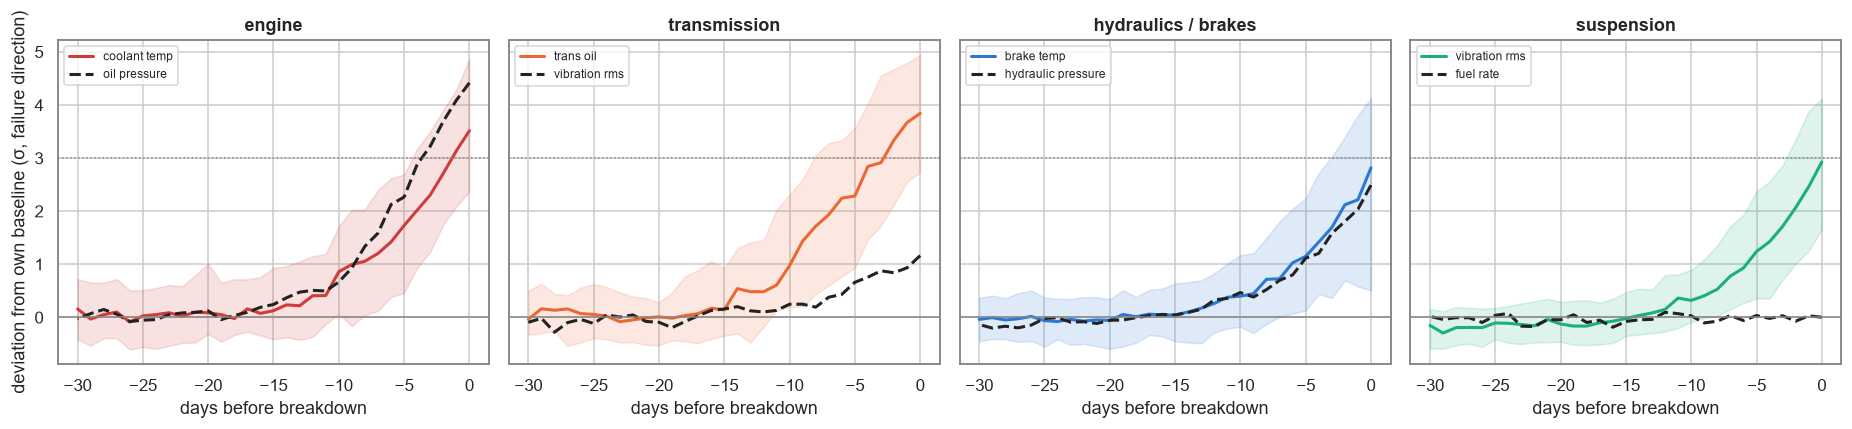

,share of breakdowns with no precursor (ground truth)
component,
engine,0.159
hydraulics_brakes,0.286
suspension,0.167
transmission,0.095


In [7]:
KEY = {"engine": ["coolant_temp_c", "oil_pressure_kpa"], "transmission": ["trans_oil_temp_c", "vibration_rms_mm_s"],
       "hydraulics_brakes": ["brake_temp_c", "hydraulic_pressure_bar"], "suspension": ["vibration_rms_mm_s", "fuel_rate_lph"]}
w = df[df.days_to_breakdown.between(0, 30)]
fig, ax = plt.subplots(1, 4, figsize=(17, 4), sharey=True)
for a, c in zip(ax, COMPS):
    s = w[w.next_component == c]
    for sens, ls in zip(KEY[c], ["-", "--"]):
        q = s.groupby("days_to_breakdown")[f"{sens}__z3"].quantile([0.25, 0.5, 0.75]).unstack()
        a.plot(-q.index, q[0.5], ls, color=COL[c] if ls == "-" else "#222", lw=2, label=sens.split("_")[0] + " " + sens.split("_")[1])
        if ls == "-": a.fill_between(-q.index, q[0.25], q[0.75], color=COL[c], alpha=0.15)
    a.axhline(0, color="#898781", lw=1); a.axhline(3, color="#898781", ls=":", lw=1)
    a.set_title(c.replace("_", " / ")); a.set_xlabel("days before breakdown"); a.legend(fontsize=8, loc="upper left")
ax[0].set_ylabel("deviation from own baseline (σ, failure direction)")
plt.tight_layout(); plt.savefig("images/precursor_signals.png", bbox_inches="tight"); plt.show()
lead_share = truth.assign(sudden=truth.lead_days == 0).groupby("component").sudden.mean()
lead_share.to_frame("share of breakdowns with no precursor (ground truth)")

Aligned on the breakdown date, each failure mode has a clear signature: falling oil pressure and rising coolant before **engine** failures, rising transmission-oil temperature before **transmission** failures, hotter brakes and falling hydraulic pressure before **hydraulic/brake** failures, rising vibration before **suspension** failures. The drift starts 10–15 days out, and the median crosses 2σ about 2–6 days before the breakdown (earliest for engine and transmission). That is the window an inspection can use. Fuel rate, by contrast, does not react to suspension wear, so not every sensor matters for every failure mode. Some failures (≈30% of hydraulic hose bursts, 10–15% of the others) have **no precursor at all**, which caps the recall any model can reach.

## 5. Baseline: per-truck control-chart rule

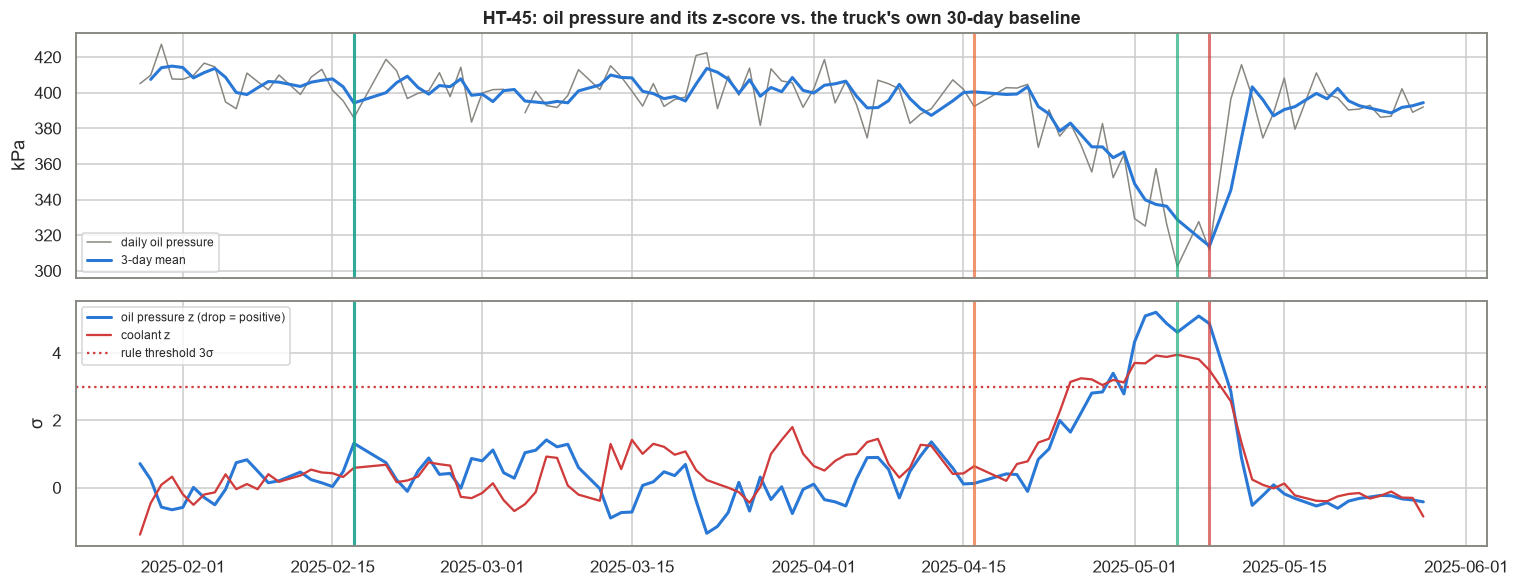

In [8]:
ex = truth[(truth.component == "engine") & (truth.lead_days >= 15) & (truth.amplitude >= 1.0)].iloc[-1]  # a typical slow engine fault
tid, t0 = ex.truck_id, pd.Timestamp(ex.failure)
g = df[(df.truck_id == tid) & df.date.between(t0 - pd.Timedelta(days=100), t0 + pd.Timedelta(days=20))]
fig, ax = plt.subplots(2, 1, figsize=(14, 5.5), sharex=True)
ax[0].plot(g.date, g.oil_pressure_kpa, color="#898781", lw=1, label="daily oil pressure")
ax[0].plot(g.date, g.oil_pressure_kpa.rolling(3, min_periods=2).mean(), color="#2a78d6", lw=2, label="3-day mean")
ax[0].set_ylabel("kPa"); ax[0].legend(fontsize=8, loc="lower left"); ax[0].set_title(f"{tid}: oil pressure and its z-score vs. the truck's own 30-day baseline")
ax[1].plot(g.date, g.oil_pressure_kpa__z3, color="#2a78d6", lw=2, label="oil pressure z (drop = positive)")
ax[1].plot(g.date, g.coolant_temp_c__z3, color="#d03b3b", lw=1.5, label="coolant z")
ax[1].axhline(3, color="#d03b3b", ls=":", label="rule threshold 3σ"); ax[1].set_ylabel("σ"); ax[1].legend(fontsize=8, loc="upper left")
for a in ax:
    for d, c in bd[(bd.truck_id == tid) & bd.date.between(g.date.min(), g.date.max())][["date", "component"]].values:
        a.axvline(d, color=COL[c], lw=2, alpha=0.7)
plt.tight_layout(); plt.savefig("images/control_chart.png", bbox_inches="tight"); plt.show()

The rule: **alert if any sensor's 3-day mean is more than *z* standard deviations from the truck's own trailing 30-day baseline** (rows t−37…t−8, so last week's drift is not absorbed into "normal"). It is simple, explainable and needs no labels, and it is the benchmark the model has to beat.

## 6. Early-warning model
**Target:** breakdown in the next 1–7 days (`y`), on operating days; the breakdown day itself is excluded.
**Features (38):** for each of 7 sensors, 3- and 7-day deviation from the truck's own baseline in σ and in units, and 7-day slope; plus max z, number of sensors above 2σ, hours since PM, days since last breakdown, age, ambient temperature, load ratio, overloading share, model and pit.
**Split by time** with a 7-day purge gap before each cut so labels do not leak across:
train Dec 2024 – Jan 2026 · validation Feb–Apr 2026 (threshold choice) · **test May–Oct 2026** (reported).

In [9]:
m = df[~df.breakdown_today & (df.date >= "2024-12-15")]
tr = m[m.date <= "2026-01-24"]; va = m[m.date.between("2026-02-01", "2026-04-23")]; te = m[m.date >= "2026-05-01"]
bd_va = bd[bd.date.between("2026-02-02", "2026-04-30")]; bd_te = bd[bd.date >= "2026-05-02"]
clf = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=31, l2_regularization=1.0, random_state=0).fit(tr[FEATS], tr.y)
p_va, p_te = (pd.Series(clf.predict_proba(s[FEATS])[:, 1], index=s.index) for s in (va, te))
z_va, z_te = va.max_z3.fillna(-9), te.max_z3.fillna(-9)
pd.DataFrame({"rows": [len(tr), len(va), len(te)], "positive rate": [tr.y.mean(), va.y.mean(), te.y.mean()],
              "breakdowns": [bd.date.between("2024-12-16", "2026-01-31").sum(), len(bd_va), len(bd_te)],
              "PR-AUC model": [np.nan, average_precision_score(va.y, p_va), average_precision_score(te.y, p_te)],
              "PR-AUC rule (max z)": [np.nan, average_precision_score(va.y, z_va), average_precision_score(te.y, z_te)],
              "ROC-AUC model": [np.nan, roc_auc_score(va.y, p_va), roc_auc_score(te.y, p_te)],
              "ROC-AUC rule": [np.nan, roc_auc_score(va.y, z_va), roc_auc_score(te.y, z_te)]},
             index=["train", "validation", "test"])

,rows,positive rate,breakdowns,PR-AUC model,PR-AUC rule (max z),ROC-AUC model,ROC-AUC rule
train,17839,0.129,377,NaN,NaN,NaN,NaN
validation,3602,0.123,75,0.588,0.507,0.811,0.769
test,8067,0.132,174,0.647,0.586,0.828,0.810


### Choosing the alert threshold in AZN (validation period)
Each alert opens an **inspection episode** (the truck is not re-alerted for 7 days). A breakdown counts as *caught* if an inspection happened 1–7 days before it. Net saving = 80% × (breakdown cost − planned-repair cost) for caught failures − inspection cost × episodes.

In [10]:
grid_m = np.round(np.arange(0.10, 0.81, 0.05), 2); grid_z = np.round(np.arange(1.5, 4.51, 0.25), 2)
sv_m = pd.DataFrame([pdm.evaluate(va[["truck_id", "date"]], p_va, t, bd_va)[0] for t in grid_m])
sv_z = pd.DataFrame([pdm.evaluate(va[["truck_id", "date"]], z_va, t, bd_va)[0] for t in grid_z])
thr_m, thr_z = sv_m.loc[sv_m.net_saving_azn.idxmax(), "threshold"], sv_z.loc[sv_z.net_saving_azn.idxmax(), "threshold"]
print(f"best model threshold {thr_m:.2f}, best rule threshold {thr_z:.2f}σ (validation)")
res_m, bd_m = pdm.evaluate(te[["truck_id", "date"]], p_te, thr_m, bd_te)
res_z, bd_z = pdm.evaluate(te[["truck_id", "date"]], z_te, thr_z, bd_te)
res_z3, _ = pdm.evaluate(te[["truck_id", "date"]], z_te, 3.0, bd_te)
# model at the same inspection load as the tuned rule (matched on validation episodes)
ep_z = sv_z.loc[sv_z.threshold == thr_z, "episodes"].iloc[0]
fine = pd.DataFrame([pdm.evaluate(va[["truck_id", "date"]], p_va, t, bd_va)[0] for t in np.round(np.arange(0.20, 0.81, 0.01), 2)])
thr_eq = fine.loc[(fine.episodes - ep_z).abs().idxmin(), "threshold"]
res_eq, bd_eq = pdm.evaluate(te[["truck_id", "date"]], p_te, thr_eq, bd_te)
months = (te.date.max() - te.date.min()).days / 30.4
T = pd.DataFrame({"Rule, textbook 3σ": res_z3, f"Rule, tuned {thr_z:.2f}σ": res_z,
                  f"GBM model, p ≥ {thr_m:.2f} (max saving)": res_m, f"GBM model, p ≥ {thr_eq:.2f} (same load as rule)": res_eq}).T
T["inspections / week"] = T.episodes / (months * 30.4 / 7)
T["saving % of breakdown cost"] = T.net_saving_azn / T.baseline_cost_azn
T["net saving AZN / year"] = T.net_saving_azn * 12 / months
T[["episodes", "inspections / week", "precision", "recall", "median_lead", "net_saving_azn", "saving % of breakdown cost", "net saving AZN / year"]]

best model threshold 0.20, best rule threshold 2.50σ (validation)


,episodes,inspections / week,precision,recall,median_lead,net_saving_azn,saving % of breakdown cost,net saving AZN / year
"Rule, textbook 3σ",145.000,5.546,0.648,0.557,3.000,"1,932,670.840",0.304,"3,852,668.429"
"Rule, tuned 2.50σ",182.000,6.962,0.604,0.661,4.000,"2,242,142.960",0.353,"4,469,583.343"
"GBM model, p ≥ 0.20 (max saving)",314.000,12.011,0.424,0.799,4.000,"2,211,631.720",0.348,"4,408,760.937"
"GBM model, p ≥ 0.38 (same load as rule)",225.000,8.607,0.560,0.759,4.000,"2,283,579.560",0.359,"4,552,184.828"


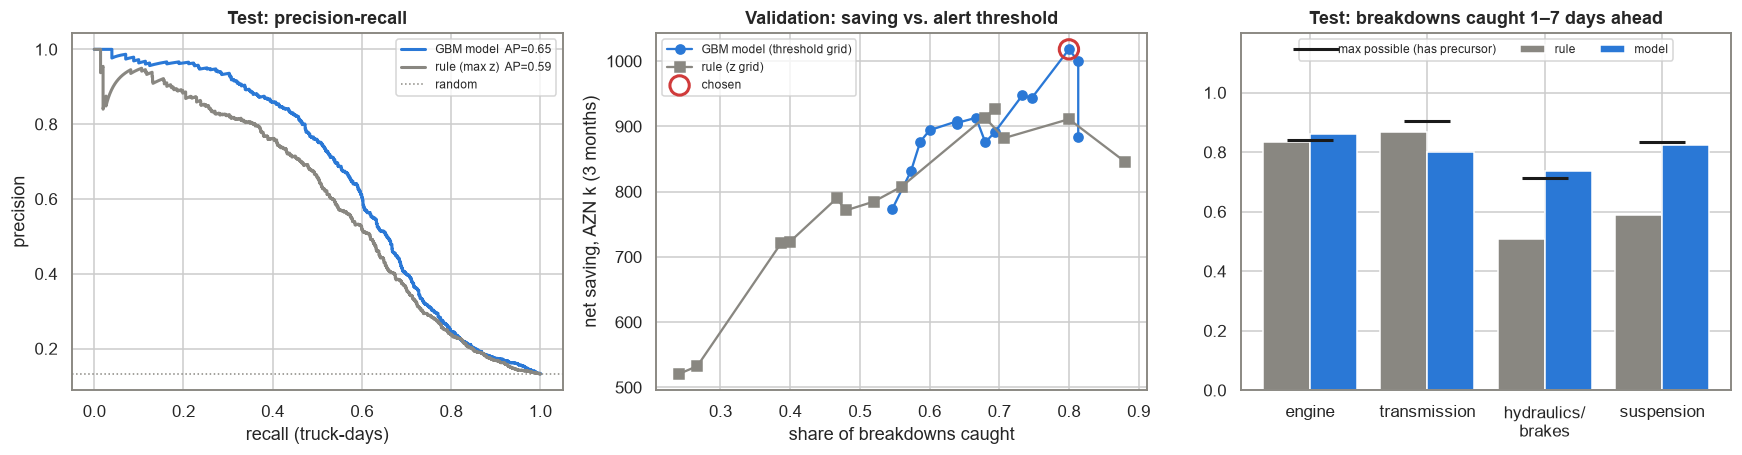

,rule caught,model caught,ceiling,test breakdowns
component,,,,
engine,0.833,0.861,0.841,36
transmission,0.867,0.800,0.905,30
hydraulics_brakes,0.509,0.737,0.714,57
suspension,0.588,0.824,0.833,51


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for s, lab, c in [(p_te, "GBM model", "#2a78d6"), (z_te, "rule (max z)", "#898781")]:
    pr, rc, _ = precision_recall_curve(te.y, s); ax[0].plot(rc, pr, color=c, lw=2, label=f"{lab}  AP={average_precision_score(te.y, s):.2f}")
ax[0].axhline(te.y.mean(), color="#898781", ls=":", lw=1, label="random"); ax[0].set_xlabel("recall (truck-days)"); ax[0].set_ylabel("precision"); ax[0].set_title("Test: precision-recall"); ax[0].legend(fontsize=8)
ax[1].plot(sv_m.recall, sv_m.net_saving_azn / 1e3, "o-", color="#2a78d6", label="GBM model (threshold grid)")
ax[1].plot(sv_z.recall, sv_z.net_saving_azn / 1e3, "s-", color="#898781", label="rule (z grid)")
ax[1].scatter(sv_m.recall[sv_m.threshold == thr_m], sv_m.net_saving_azn[sv_m.threshold == thr_m] / 1e3, s=160, facecolor="none", edgecolor="#d03b3b", lw=2, zorder=5, label="chosen")
ax[1].set_xlabel("share of breakdowns caught"); ax[1].set_ylabel("net saving, AZN k (3 months)"); ax[1].set_title("Validation: saving vs. alert threshold"); ax[1].legend(fontsize=8)
rc = bd_m.groupby("component").lead_days.apply(lambda s: s.notna().mean()).reindex(COMPS)
rz = bd_z.groupby("component").lead_days.apply(lambda s: s.notna().mean()).reindex(COMPS)
xx = np.arange(4); ax[2].bar(xx - 0.2, rz, 0.4, color="#898781", label="rule"); ax[2].bar(xx + 0.2, rc, 0.4, color="#2a78d6", label="model")
ax[2].plot(xx, 1 - lead_share.reindex(COMPS), "k_", ms=30, mew=2, label="max possible (has precursor)")
ax[2].set_xticks(xx); ax[2].set_xticklabels([c.replace("_brakes", "/\nbrakes") for c in COMPS]); ax[2].set_ylim(0, 1.2); ax[2].set_yticks(np.arange(0, 1.01, 0.2))
ax[2].set_title("Test: breakdowns caught 1–7 days ahead"); ax[2].legend(fontsize=8, loc="upper center", ncol=3)
plt.tight_layout(); plt.savefig("images/model_evaluation.png", bbox_inches="tight"); plt.show()
pd.DataFrame({"rule caught": rz, "model caught": rc, "ceiling": 1 - lead_share.reindex(COMPS), "test breakdowns": bd_te.component.value_counts().reindex(COMPS)})

### What the model looks at (permutation importance on the test period, grouped by sensor)

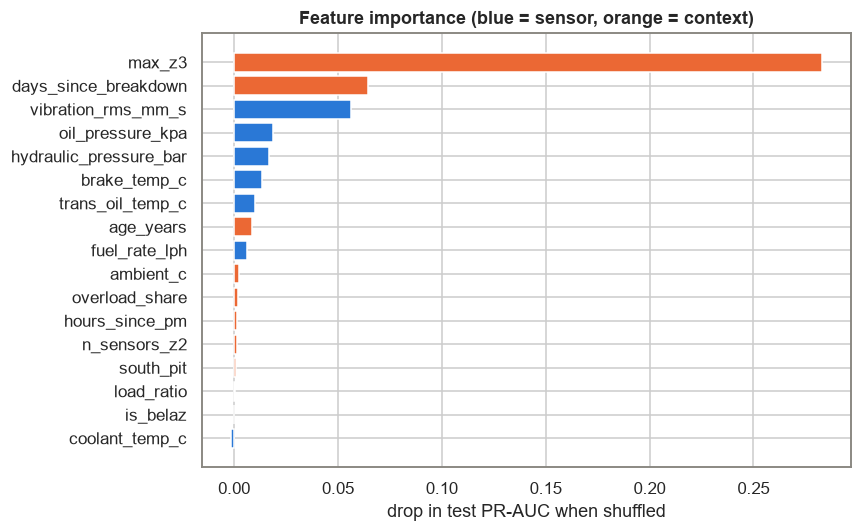

,Δ PR-AUC
max_z3,0.283
days_since_breakdown,0.064
vibration_rms_mm_s,0.056
oil_pressure_kpa,0.019
hydraulic_pressure_bar,0.017
brake_temp_c,0.014
trans_oil_temp_c,0.010
age_years,0.008
fuel_rate_lph,0.006
ambient_c,0.003


In [12]:
pi = permutation_importance(clf, te[FEATS], te.y, scoring="average_precision", n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=FEATS)
grp = imp.groupby(lambda f: f.split("__")[0] if "__" in f else f).sum().sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(grp.index, grp.values, color=["#2a78d6" if g in pdm.SENS else "#eb6834" for g in grp.index])
ax.set_xlabel("drop in test PR-AUC when shuffled"); ax.set_title("Feature importance (blue = sensor, orange = context)")
plt.tight_layout(); plt.savefig("images/feature_importance.png", bbox_inches="tight"); plt.show()
grp.sort_values(ascending=False).head(10).to_frame("Δ PR-AUC")

The strongest single feature is the same one the rule uses (`max_z3`), so the model is mostly a better-calibrated version of the rule. The model adds three things. **Days since the last breakdown** matters because a truck's baseline is distorted for a few weeks after a repair. **Vibration** and other multi-day trends count even when they are below 3σ. And it combines weak signals that move together (brake temperature up *and* hydraulic pressure down). This is why it catches many more hydraulic/brake and suspension faults than the single-sensor rule. *(A catch rate slightly above the "max possible" line happens when an alert raised for one reason is followed by an unrelated failure within 7 days.)*

## 7. Today's watch list (31 Oct 2026)

In [13]:
last = df[df.date == df.date.max()].copy()
last["risk_7d"] = clf.predict_proba(last[FEATS])[:, 1]
zs = last[[f"{c}__z3" for c in pdm.SENS]].fillna(-99)
last["main_signal"] = zs.idxmax(axis=1).str.replace("__z3", "") + " (" + zs.max(axis=1).round(1).astype(str) + "σ)"
watch = last.sort_values("risk_7d", ascending=False)[["truck_id", "model", "pit", "risk_7d", "main_signal", "hours_since_pm", "age_years"]]
print(f"{(last.risk_7d >= thr_m).sum()} trucks above the alert threshold today")
watch.head(8).round(2)

7 trucks above the alert threshold today


,truck_id,model,pit,risk_7d,main_signal,hours_since_pm,age_years
8851,HT-13,Komatsu HD785,North Pit,0.990,brake_temp_c (6.0σ),216.700,6.830
675,HT-01,BelAZ 7555B,South Pit,0.980,hydraulic_pressure_bar (2.9σ),0.000,8.830
21155,HT-31,BelAZ 7555B,North Pit,0.910,vibration_rms_mm_s (3.5σ),601.800,10.160
1359,HT-02,CAT 777G,North Pit,0.770,trans_oil_temp_c (4.0σ),215.900,5.080
23873,HT-35,Komatsu HD785,North Pit,0.770,trans_oil_temp_c (2.6σ),102.700,6.080
20469,HT-30,Komatsu HD785,South Pit,0.290,vibration_rms_mm_s (1.2σ),0.000,6.080
23193,HT-34,CAT 777G,South Pit,0.210,fuel_rate_lph (2.9σ),77.700,5.500
6103,HT-09,CAT 777G,South Pit,0.170,oil_pressure_kpa (1.1σ),499.000,4.080


## 8. Findings & recommendations

In [14]:
rows = [
 ("Cost of breakdowns", f"{len(bd)} breakdowns in 2 years, AZN {bd.unplanned_azn.sum()/2e6:.2f} M a year; {(bd.downtime_h*pdm.MARGIN_PER_H).sum()/bd.unplanned_azn.sum():.0%} of it is lost haulage, not parts",
  "Track unplanned downtime hours as the headline maintenance KPI, next to availability"),
 ("Late PM", f"Rate {r_pm.per_1000h.iloc[-1]:.2f} vs {r_pm.per_1000h.iloc[:3].mean():.2f} per 1,000 h when PM is > 550 h late; {(pm_at > 550).mean():.0%} of PMs are late",
  "Hard cap: no truck past 550 h without a PM; plan PM slots from the engine-hour forecast, not the calendar"),
 ("South Pit", f"Suspension/transmission/brake rate {pp.loc['South Pit', COMPS[1:]].sum():.2f} vs {pp.loc['North Pit', COMPS[1:]].sum():.2f} per 1,000 h on North Pit",
  "Ramp/haul-road maintenance and payload control (on-board weighing alerts at > 110%) on South Pit"),
 ("Sensors warn early", "Drift starts 10–15 days out and passes 2σ 2–6 days before most failures", "Use telemetry daily, not only after a failure"),
 ("Rule vs model (test)", f"Tuned {thr_z:.1f}σ rule: {res_z['recall']:.0%} caught, AZN {res_z['net_saving_azn']*12/months/1e6:.2f} M/yr. Model at similar load: {res_eq['recall']:.0%} caught, AZN {res_eq['net_saving_azn']*12/months/1e6:.2f} M/yr",
  "Go live with the tuned rule now: it gets most of the value with no ML. Add the model for availability: it catches more of the hydraulic and suspension faults"),
 ("Value", f"Net saving ≈ AZN {res_z['net_saving_azn']*12/months/1e6:.1f} M a year ({res_z['net_saving_azn']/res_z['baseline_cost_azn']:.0%} of breakdown cost) with ~{T.iloc[1]['inspections / week']:.0f} inspections a week",
  "Daily watch list to the shift maintenance planner; inspect flagged trucks at the next shift change"),
 ("Threshold", "The textbook 3σ rule leaves money on the table vs. the tuned 2.5σ", "Tune alert thresholds on cost, not on statistical convention, and re-tune every quarter"),
 ("Limits", f"~{lead_share.mean():.0%} of failures have no precursor (hose bursts)", "Keep run-to-failure spares for hoses; preventive replacement by hours on hydraulic hoses"),
]
pd.DataFrame(rows, columns=["Area", "Evidence", "Recommendation"])

,Area,Evidence,Recommendation
0,Cost of breakdowns,"657 breakdowns in 2 years, AZN 11.98 M a year; 43% of it is lost haulage, not parts","Track unplanned downtime hours as the headline maintenance KPI, next to availability"
1,Late PM,"Rate 1.42 vs 1.04 per 1,000 h when PM is > 550 h late; 29% of PMs are late","Hard cap: no truck past 550 h without a PM; plan PM slots from the engine-hour forecast, not the calendar"
2,South Pit,"Suspension/transmission/brake rate 1.01 vs 0.71 per 1,000 h on North Pit",Ramp/haul-road maintenance and payload control (on-board weighing alerts at > 110%) on South Pit
3,Sensors warn early,Drift starts 10–15 days out and passes 2σ 2–6 days before most failures,"Use telemetry daily, not only after a failure"
4,Rule vs model (test),"Tuned 2.5σ rule: 66% caught, AZN 4.47 M/yr. Model at similar load: 76% caught, AZN 4.55 M/yr",Go live with the tuned rule now: it gets most of the value with no ML. Add the model for availability: it catches more of the hydraulic and suspension faults
5,Value,Net saving ≈ AZN 4.5 M a year (35% of breakdown cost) with ~7 inspections a week,Daily watch list to the shift maintenance planner; inspect flagged trucks at the next shift change
6,Threshold,The textbook 3σ rule leaves money on the table vs. the tuned 2.5σ,"Tune alert thresholds on cost, not on statistical convention, and re-tune every quarter"
7,Limits,~18% of failures have no precursor (hose bursts),Keep run-to-failure spares for hoses; preventive replacement by hours on hydraulic hoses


**Bottom line:** breakdowns cost this fleet well over a million AZN a year, mostly in lost haulage. Two cheap fixes come first: **stop PMs going late** and **control overloading on South Pit**. On top of that, the trucks' own sensors give a warning of several days for most failures. A **per-truck z-score rule with a cost-tuned threshold** pays for its inspections many times over. The gradient-boosted model ranks risk better (higher PR-AUC) and, at a similar inspection load, catches about 10 points more failures, but it earns only ~2% more, because its extra catches are mostly cheap hydraulic and suspension faults. An honest result: **go live with the simple rule first**, then add the model where truck availability is worth more than inspection hours.

*Caveats: synthetic data with a known structure, so real precursors will be noisier. Money figures rest on the stated assumptions (420 AZN/h margin, 80% find rate, 35%/30% planned cost/downtime). An inspection can also find faults other than the predicted one, which this evaluation ignores (conservative). The model should be retrained quarterly and monitored for drift as trucks age.*